In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest

Libraries loaded successfully!


In [2]:
results = pd.read_csv("forecast_results.csv")

print("Shape:", results.shape)
results.head()

Shape: (1709, 5)


,DateTime,Actual,Predicted,Error,Absolute_Error
0,2017-10-20 19:00:00,44637.899343,45326.400,-688.499094,688.499094
1,2017-10-20 20:00:00,43882.713347,44456.086,-573.372591,573.372591
2,2017-10-20 21:00:00,41498.468270,41149.867,348.601083,348.601083
3,2017-10-20 22:00:00,37074.485777,36107.480,967.005308,967.005308
4,2017-10-20 23:00:00,31948.884027,31519.790,429.094964,429.094964


In [3]:
print(results.info())
print("\nMissing values:")
print(results.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1709 entries, 0 to 1708
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   DateTime        1709 non-null   object 
 1   Actual          1709 non-null   float64
 2   Predicted       1709 non-null   float64
 3   Error           1709 non-null   float64
 4   Absolute_Error  1709 non-null   float64
dtypes: float64(4), object(1)
memory usage: 66.9+ KB
None

Missing values:
DateTime          0
Actual            0
Predicted         0
Error             0
Absolute_Error    0
dtype: int64


In [4]:
results["DateTime"] = pd.to_datetime(results["DateTime"])

results["Residual"] = (
    results["Actual"] - results["Predicted"]
)

results["Absolute_Residual"] = (
    results["Residual"].abs()
)

results.head()

,DateTime,Actual,Predicted,Error,Absolute_Error,Residual,Absolute_Residual
0,2017-10-20 19:00:00,44637.899343,45326.400,-688.499094,688.499094,-688.500657,688.500657
1,2017-10-20 20:00:00,43882.713347,44456.086,-573.372591,573.372591,-573.372653,573.372653
2,2017-10-20 21:00:00,41498.468270,41149.867,348.601083,348.601083,348.601270,348.601270
3,2017-10-20 22:00:00,37074.485777,36107.480,967.005308,967.005308,967.005777,967.005777
4,2017-10-20 23:00:00,31948.884027,31519.790,429.094964,429.094964,429.094027,429.094027


In [5]:
print(results["Residual"].describe())

count    1709.000000
mean     -104.571141
std      1213.604832
min     -6130.213852
25%      -788.022398
50%      -146.027957
75%       517.663593
max      4654.755400
Name: Residual, dtype: float64


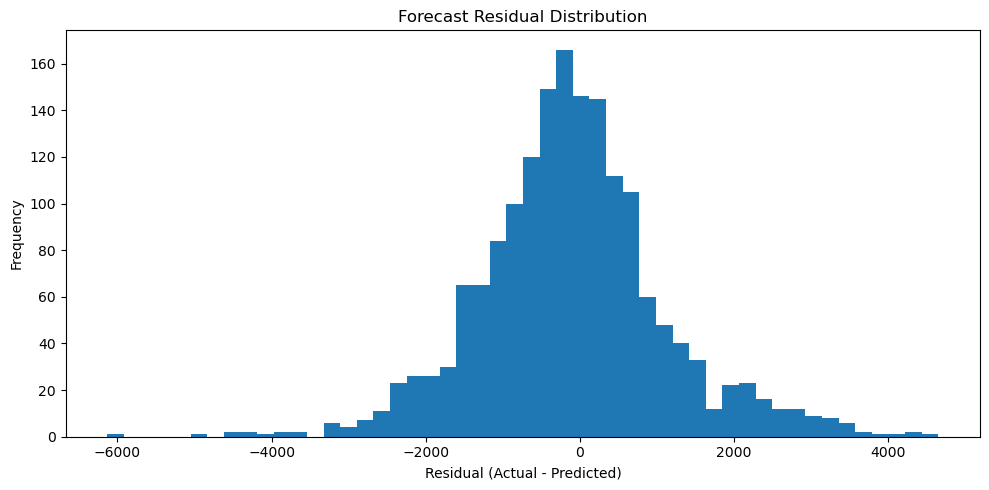

In [6]:
plt.figure(figsize=(10, 5))

plt.hist(
    results["Residual"],
    bins=50
)

plt.title("Forecast Residual Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

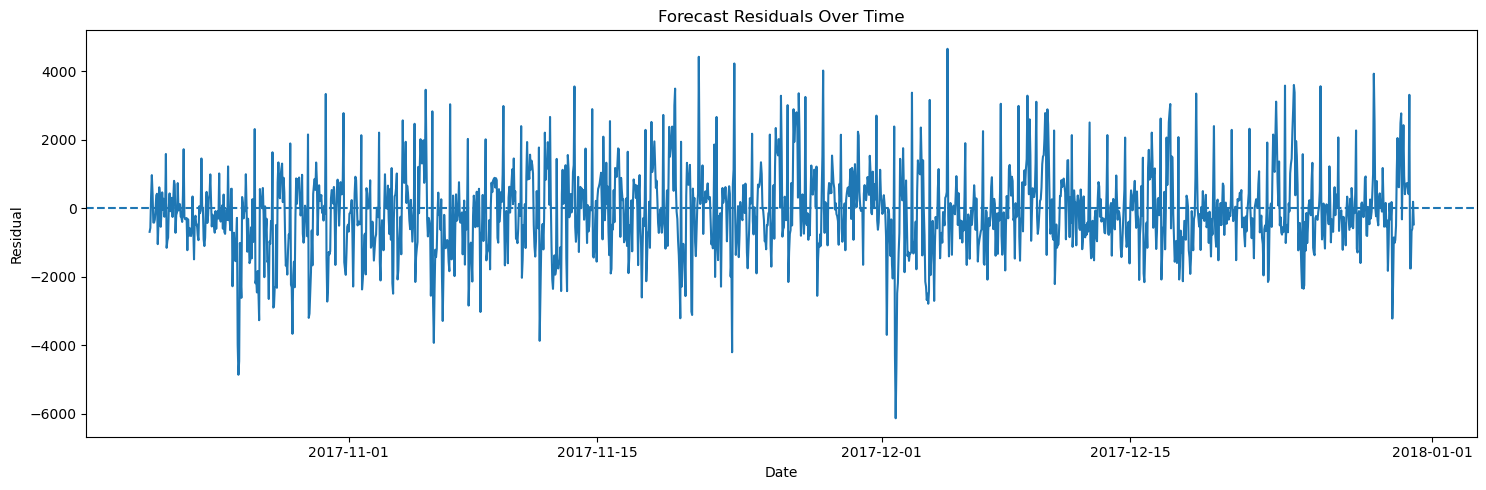

In [7]:
plt.figure(figsize=(15, 5))

plt.plot(
    results["DateTime"],
    results["Residual"]
)

plt.axhline(0, linestyle="--")

plt.title("Forecast Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Residual")

plt.tight_layout()
plt.show()

In [8]:
results.describe()

,DateTime,Actual,Predicted,Error,Absolute_Error,Residual,Absolute_Residual
count,1709,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000
mean,2017-11-25 09:00:00.000000256,29379.234626,29483.805767,-104.571138,903.718007,-104.571141,903.717997
min,2017-10-20 19:00:00,17908.238277,17158.014000,-6130.214164,0.173575,-6130.213852,0.174357
25%,2017-11-07 14:00:00,23401.312912,23072.120000,-788.022820,297.745150,-788.022398,297.745572
50%,2017-11-25 09:00:00,29589.860583,30412.357000,-146.028222,664.855820,-146.027957,664.855898
75%,2017-12-13 04:00:00,33527.179487,33455.992000,517.664000,1272.630148,517.663593,1272.629788
max,2017-12-30 23:00:00,46354.135670,46643.676000,4654.755244,6130.214164,4654.755400,6130.213852
std,NaN,6085.096677,6532.743618,1213.604845,816.451985,1213.604832,816.451977


In [9]:
q1 = results["Absolute_Residual"].quantile(0.25)
q3 = results["Absolute_Residual"].quantile(0.75)

iqr = q3 - q1

upper_threshold = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Anomaly Threshold:", upper_threshold)

Q1: 297.74557166666636
Q3: 1272.6297883333318
IQR: 974.8842166666655
Anomaly Threshold: 2734.95611333333


In [10]:
results["Residual_Anomaly"] = (
    results["Absolute_Residual"] > upper_threshold
)

print(
    "Potential anomalies:",
    results["Residual_Anomaly"].sum()
)

print(
    "Normal observations:",
    (~results["Residual_Anomaly"]).sum()
)

Potential anomalies: 65
Normal observations: 1644


In [11]:
anomalies = results[
    results["Residual_Anomaly"]
].sort_values(
    "Absolute_Residual",
    ascending=False
)

anomalies.head(20)

,DateTime,Actual,Predicted,Error,Absolute_Error,Residual,Absolute_Residual,Residual_Anomaly
1008,2017-12-01 19:00:00,35371.356148,41501.570,-6130.214164,6130.214164,-6130.213852,6130.213852,True
120,2017-10-25 19:00:00,41264.245073,46125.080,-4860.833052,4860.833052,-4860.834927,4860.834927,True
1078,2017-12-04 17:00:00,37575.665400,32920.910,4654.755244,4654.755244,4654.755400,4654.755400,True
1009,2017-12-01 20:00:00,35434.220532,40047.938,-4613.716968,4613.716968,-4613.717468,4613.717468,True
121,2017-10-25 20:00:00,39878.862145,44341.344,-4462.481605,4462.481605,-4462.481855,4462.481855,True
742,2017-11-20 17:00:00,36802.051282,32380.174,4421.877454,4421.877454,4421.877282,4421.877282,True
1007,2017-12-01 18:00:00,35566.032953,39834.330,-4268.295172,4268.295172,-4268.297047,4268.297047,True
790,2017-11-22 17:00:00,38378.461538,34152.130,4226.332632,4226.332632,4226.331538,4226.331538,True
787,2017-11-22 14:00:00,28447.179487,32650.982,-4203.802935,4203.802935,-4203.802513,4203.802513,True
910,2017-11-27 17:00:00,38199.999998,34180.332,4019.667967,4019.667967,4019.667998,4019.667998,True


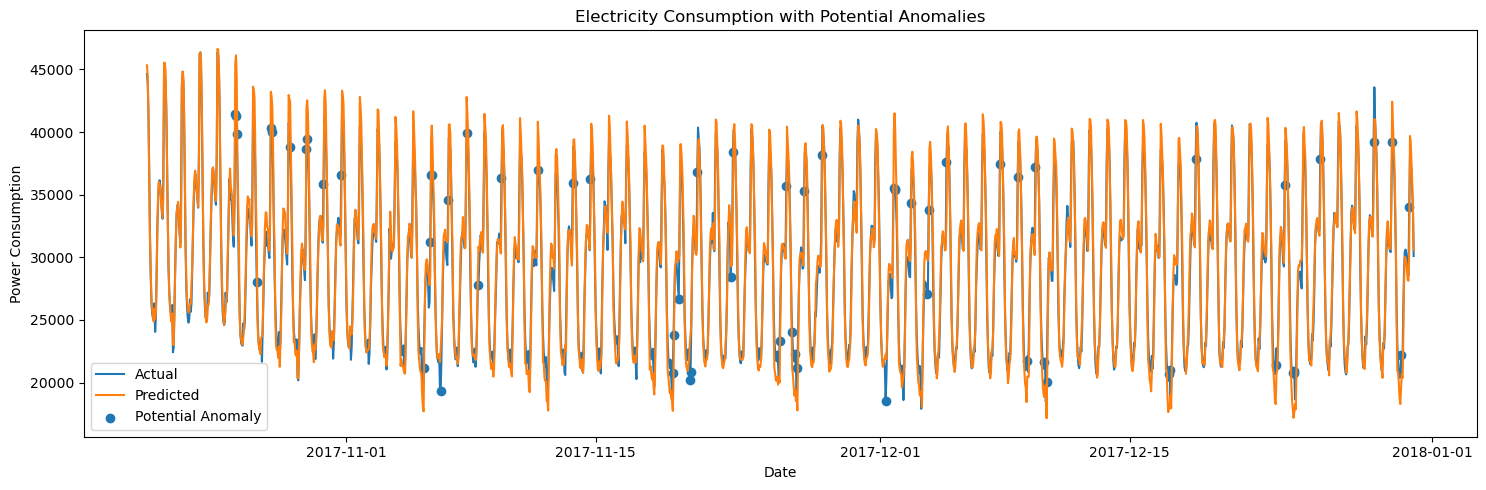

In [12]:
plt.figure(figsize=(15, 5))

plt.plot(
    results["DateTime"],
    results["Actual"],
    label="Actual"
)

plt.plot(
    results["DateTime"],
    results["Predicted"],
    label="Predicted"
)

plt.scatter(
    anomalies["DateTime"],
    anomalies["Actual"],
    label="Potential Anomaly"
)

plt.title("Electricity Consumption with Potential Anomalies")
plt.xlabel("Date")
plt.ylabel("Power Consumption")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
print("Total observations:", len(results))
print("Potential anomalies:", results["Residual_Anomaly"].sum())
print(
    "Anomaly percentage:",
    results["Residual_Anomaly"].mean() * 100,
    "%"
)

Total observations: 1709
Potential anomalies: 65
Anomaly percentage: 3.8033937975424226 %


In [14]:
anomaly_features = [
    "Actual",
    "Predicted",
    "Residual",
    "Absolute_Residual"
]

X_anomaly = results[anomaly_features].copy()

X_anomaly.head()

,Actual,Predicted,Residual,Absolute_Residual
0,44637.899343,45326.400,-688.500657,688.500657
1,43882.713347,44456.086,-573.372653,573.372653
2,41498.468270,41149.867,348.601270,348.601270
3,37074.485777,36107.480,967.005777,967.005777
4,31948.884027,31519.790,429.094027,429.094027


In [15]:
isolation_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

isolation_model.fit(X_anomaly)

IsolationForest(n_estimators=200, random_state=42)

In [16]:
results["Isolation_Prediction"] = isolation_model.predict(
    X_anomaly
)

In [17]:
results["Isolation_Anomaly"] = (
    results["Isolation_Prediction"] == -1
)

print(
    "Isolation Forest anomalies:",
    results["Isolation_Anomaly"].sum()
)

Isolation Forest anomalies: 339


In [18]:
comparison = pd.DataFrame({
    "Method": [
        "Residual + IQR",
        "Isolation Forest"
    ],
    "Anomalies": [
        results["Residual_Anomaly"].sum(),
        results["Isolation_Anomaly"].sum()
    ]
})

comparison

,Method,Anomalies
0,Residual + IQR,65
1,Isolation Forest,339


In [19]:
X_isolation = results[["Absolute_Residual"]].copy()

print(X_isolation.head())

   Absolute_Residual
0         688.500657
1         573.372653
2         348.601270
3         967.005777
4         429.094027


In [20]:
anomaly_rate = (
    results["Residual_Anomaly"].mean()
)

print("Calibrated contamination:", anomaly_rate)

Calibrated contamination: 0.038033937975424224


In [21]:
isolation_model = IsolationForest(
    n_estimators=200,
    contamination=anomaly_rate,
    random_state=42
)

isolation_model.fit(X_isolation)

IsolationForest(contamination=np.float64(0.038033937975424224),
                n_estimators=200, random_state=42)

In [22]:
results["Isolation_Prediction"] = (
    isolation_model.predict(X_isolation)
)

results["Isolation_Anomaly"] = (
    results["Isolation_Prediction"] == -1
)

print(
    "Isolation Forest anomalies:",
    results["Isolation_Anomaly"].sum()
)

Isolation Forest anomalies: 65


In [23]:
comparison = pd.DataFrame({
    "Method": [
        "Residual + IQR",
        "Isolation Forest"
    ],
    "Anomalies": [
        results["Residual_Anomaly"].sum(),
        results["Isolation_Anomaly"].sum()
    ]
})

comparison

,Method,Anomalies
0,Residual + IQR,65
1,Isolation Forest,65


In [24]:
results["Both_Anomaly"] = (
    results["Residual_Anomaly"] &
    results["Isolation_Anomaly"]
)

print(
    "Both methods agree:",
    results["Both_Anomaly"].sum()
)

Both methods agree: 65


In [27]:
both_anomalies = (
    results["Residual_Anomaly"] &
    results["Isolation_Anomaly"]
)

print("Residual + IQR anomalies:", results["Residual_Anomaly"].sum())
print("Isolation Forest anomalies:", results["Isolation_Anomaly"].sum())
print("Both methods agree:", both_anomalies.sum())

Residual + IQR anomalies: 65
Isolation Forest anomalies: 65
Both methods agree: 65


In [28]:
results["Both_Anomaly"] = both_anomalies

print("Agreement percentage:",
      results["Both_Anomaly"].mean() * 100, "%")

Agreement percentage: 3.8033937975424226 %


In [29]:
final_anomalies = results[
    results["Both_Anomaly"]
].copy()

final_anomalies = final_anomalies.sort_values(
    "Absolute_Residual",
    ascending=False
)

final_anomalies.head(20)

,DateTime,Actual,Predicted,Error,Absolute_Error,Residual,Absolute_Residual,Residual_Anomaly,Isolation_Prediction,Isolation_Anomaly,Both_Anomaly
1008,2017-12-01 19:00:00,35371.356148,41501.570,-6130.214164,6130.214164,-6130.213852,6130.213852,True,-1,True,True
120,2017-10-25 19:00:00,41264.245073,46125.080,-4860.833052,4860.833052,-4860.834927,4860.834927,True,-1,True,True
1078,2017-12-04 17:00:00,37575.665400,32920.910,4654.755244,4654.755244,4654.755400,4654.755400,True,-1,True,True
1009,2017-12-01 20:00:00,35434.220532,40047.938,-4613.716968,4613.716968,-4613.717468,4613.717468,True,-1,True,True
121,2017-10-25 20:00:00,39878.862145,44341.344,-4462.481605,4462.481605,-4462.481855,4462.481855,True,-1,True,True
742,2017-11-20 17:00:00,36802.051282,32380.174,4421.877454,4421.877454,4421.877282,4421.877282,True,-1,True,True
1007,2017-12-01 18:00:00,35566.032953,39834.330,-4268.295172,4268.295172,-4268.297047,4268.297047,True,-1,True,True
790,2017-11-22 17:00:00,38378.461538,34152.130,4226.332632,4226.332632,4226.331538,4226.331538,True,-1,True,True
787,2017-11-22 14:00:00,28447.179487,32650.982,-4203.802935,4203.802935,-4203.802513,4203.802513,True,-1,True,True
910,2017-11-27 17:00:00,38199.999998,34180.332,4019.667967,4019.667967,4019.667998,4019.667998,True,-1,True,True


In [30]:
import joblib

joblib.dump(
    isolation_model,
    "isolation_forest_anomaly_model.pkl"
)

print("Isolation Forest model saved successfully!")

Isolation Forest model saved successfully!


In [31]:
anomaly_config = {
    "residual_iqr_threshold": upper_threshold,
    "contamination": anomaly_rate
}

joblib.dump(
    anomaly_config,
    "anomaly_detection_config.pkl"
)

print("Anomaly configuration saved successfully!")

Anomaly configuration saved successfully!


In [33]:
results["Final_Anomaly"] = results["Both_Anomaly"]

print(
    "Final anomalies:",
    results["Final_Anomaly"].sum()
)

print(
    "Final anomaly percentage:",
    results["Final_Anomaly"].mean() * 100,
    "%"
)

Final anomalies: 65
Final anomaly percentage: 3.8033937975424226 %


In [34]:
results["Anomaly_Type"] = np.where(
    results["Final_Anomaly"] &
    (results["Residual"] > 0),
    "High Consumption",
    np.where(
        results["Final_Anomaly"] &
        (results["Residual"] < 0),
        "Low Consumption",
        "Normal"
    )
)

print(
    results["Anomaly_Type"].value_counts()
)

Anomaly_Type
Normal              1644
High Consumption      40
Low Consumption       25
Name: count, dtype: int64


In [35]:
final_anomalies = results[
    results["Final_Anomaly"]
][[
    "DateTime",
    "Actual",
    "Predicted",
    "Residual",
    "Absolute_Residual",
    "Anomaly_Type"
]].sort_values(
    "Absolute_Residual",
    ascending=False
)

final_anomalies.head(20)

,DateTime,Actual,Predicted,Residual,Absolute_Residual,Anomaly_Type
1008,2017-12-01 19:00:00,35371.356148,41501.570,-6130.213852,6130.213852,Low Consumption
120,2017-10-25 19:00:00,41264.245073,46125.080,-4860.834927,4860.834927,Low Consumption
1078,2017-12-04 17:00:00,37575.665400,32920.910,4654.755400,4654.755400,High Consumption
1009,2017-12-01 20:00:00,35434.220532,40047.938,-4613.717468,4613.717468,Low Consumption
121,2017-10-25 20:00:00,39878.862145,44341.344,-4462.481855,4462.481855,Low Consumption
742,2017-11-20 17:00:00,36802.051282,32380.174,4421.877282,4421.877282,High Consumption
1007,2017-12-01 18:00:00,35566.032953,39834.330,-4268.297047,4268.297047,Low Consumption
790,2017-11-22 17:00:00,38378.461538,34152.130,4226.331538,4226.331538,High Consumption
787,2017-11-22 14:00:00,28447.179487,32650.982,-4203.802513,4203.802513,Low Consumption
910,2017-11-27 17:00:00,38199.999998,34180.332,4019.667998,4019.667998,High Consumption


In [36]:
final_anomalies.to_csv(
    "final_anomalies.csv",
    index=False
)

results.to_csv(
    "anomaly_results.csv",
    index=False
)

print("Final anomaly files saved successfully!")

Final anomaly files saved successfully!
